In [21]:
import random
import numpy as np
import matplotlib.pyplot as plt

# Mean, Variance, Standard Deviation

In [2]:
# Vectorized

N = 1000
x = np.random.uniform(-1, 1, size = N)
xm = np.mean(x)
xv = np.var(x)
xs = np.std(x)
print('%10d mean: %12.5e stdev: %12.5e var: %12.5e' % (N, xm, xs, xv))

      1000 mean: -1.18106e-02 stdev:  5.87276e-01 var:  3.44893e-01


In [3]:
# Old school way - extremely slow

N = 100
sm = 0
sv = 0

for i in range(1, N+1):
    x = np.random.uniform(-1, 1)
    sm += x
    sv += x**2

    # Print out mu and sigma 10 times
    if i % (N/10) == 0:
        xm = sm / i
        xs = np.sqrt(sv / i - xm**2)
        print('%10d mean: %12.5e stdev: %12.5e' % (i, xm, xs))

        10 mean: -2.37438e-01 stdev:  4.99105e-01
        20 mean: -1.13090e-01 stdev:  5.71402e-01
        30 mean:  4.11519e-03 stdev:  5.74134e-01
        40 mean: -8.51115e-04 stdev:  5.61940e-01
        50 mean: -2.84800e-02 stdev:  5.85123e-01
        60 mean: -8.61780e-02 stdev:  5.72694e-01
        70 mean: -5.15426e-02 stdev:  5.75412e-01
        80 mean: -6.22046e-02 stdev:  5.73773e-01
        90 mean: -4.75247e-02 stdev:  5.70048e-01
       100 mean: -2.87390e-02 stdev:  5.74995e-01


Notes: as N gets larger, the mean starts to approach 0. The theoretical value of sigma (standard deviation) as $N \to 0$ is $\sqrt{1 / 3} \approx 0.57735$ 

# Several Ways to Produce and Visualize Random Numbers

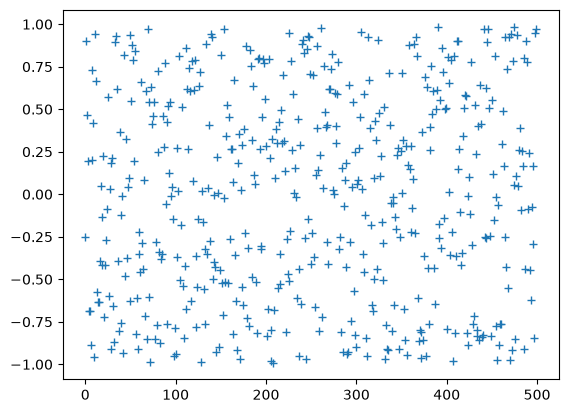

In [4]:
# Visualize random numbers - compare to linear congruent generator method

np.random.seed(42)                         # seeding ensures you get the same result each time
N = 500                                    # number of samples
x = range(N)                               # x-axis
y = [np.random.uniform(-1,1) for i in x]   # random number generation

plt.plot(x, y, '+')

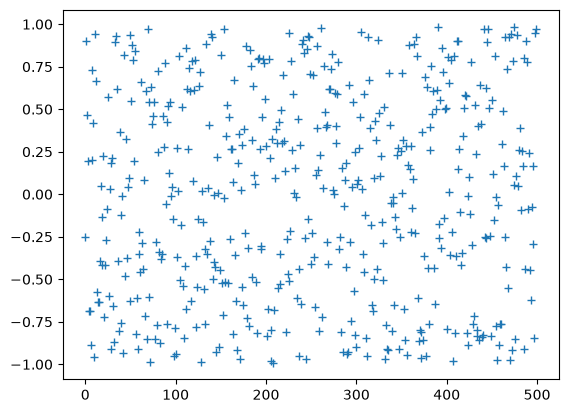

In [5]:
# Visualize random numbers - quicker

np.random.seed(42)                                # seeding ensures you get the same result each time
N = 500                                           # I could also set x = range(N) and then the in the loop [for i in x]
y = [np.random.uniform(-1,1) for i in range(N)]   # random number generation

plt.plot(y, '+')

(array([107.,  96.,  92.,  99., 108.,  99.,  89., 111., 103.,  96.]),
 array([0.00118373, 0.1009154 , 0.20064706, 0.30037872, 0.40011039,
        0.49984205, 0.59957371, 0.69930537, 0.79903704, 0.8987687 ,
        0.99850036]),
 <BarContainer object of 10 artists>)

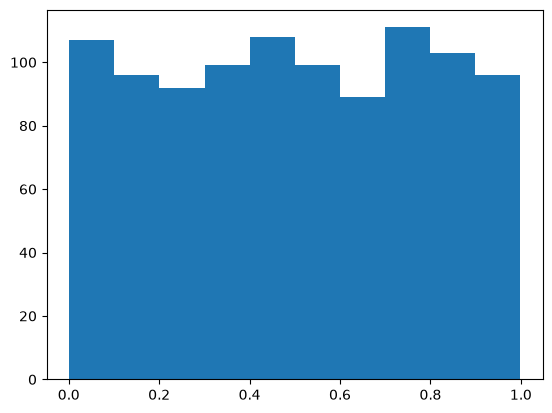

In [22]:
# How to plot a histogram of a uniform distribution

samples = [random.random() for i in range(1000)]
plt.hist(samples)

In [ ]:
# And a normal (Gaussian) distribution:

x = np.random.normal(50, 25, 1000)          # Mean, Std Deviation, Size
plt.hist(x)

The next few cells highlight how seed() works.

In [ ]:
import random

random.seed(2)
['%.2f' % random.random() for i in range(10)]

In [ ]:
['%.2f' % random.random() for i in range(10)]

In [ ]:
random.seed(2)
['%.2f' % random.random() for i in range(10)]

In [ ]:
# using numpy, you select the range of numbers then how many you want
# no loops
samples_np = np.random.uniform(-1, 1, size=1000)
# or just one time
rand_np = np.random.uniform(-1,1)
rand_int = np.random.randint(0, N)
print(rand_int)
print(rand_np)
#print(samples_np)

# note = np.random.randint(a, b, N) does not include b, have to use np.random.randint(a, b+1, N)
# however, np.random.random_integers(a, b, N) does include b

Thinking out loud: my main loop needs to have an if where it compares the probability (of moving boxes) to a random number. \
\
if np.random.randint(0, N) > (n / N): \
    change state from 0 to 1 \
\
So - how this all work when checking both sides? The particle chosen is obviously the array, particles[i]... \
\
so maybe, if i = 0, then use n / N as the probability \
\
and if i = 1 then use (N - n) / N as the probability to compare to. \
